# Mesh frontier repair: reproducible analysis

All tables use the frozen new timing cohort. Ratios above one favor the candidate. Correct no-path replay answers count as complete; navigation requires reaching the goal. Allocation data come from a separate pass.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
ad = root / 'cpp/mesh_envelope/results/full/analysis'
meta = json.loads((ad/'analysis.json').read_text())
assert meta['status'] == 'passed'
for name, sha in meta['tables_sha256'].items():
    assert hashlib.sha256((ad/name).read_bytes()).hexdigest() == sha
{k: meta[k] for k in ['scenarios','timed_runs','memory_runs','timed_calls','exact_cost_disagreements','capped_calls','allocation_matched_rows']}

{'scenarios': 228,
 'timed_runs': 11340,
 'memory_runs': 3780,
 'timed_calls': 293487,
 'exact_cost_disagreements': 0,
 'capped_calls': 36,
 'allocation_matched_rows': 97829}

In [2]:
summary = pd.read_csv(ad/'summary.csv')
new = ['envelope_mesh','dual_mesh','circuit_mesh']
display(summary[summary.method.isin(new) & summary.baseline.eq('best_control')][['cohort','control','method','pairs','full_speedup','repair_speedup','memory_multiplier','wins_10pct']])
map_pairs = pd.read_csv(ad/'map_pairs.csv')
display(map_pairs[map_pairs.method.eq('dual_mesh') & map_pairs.baseline.eq('best_control')][['cohort','control','map','pairs','full_speedup','repair_speedup']])

,cohort,control,method,pairs,full_speedup,repair_speedup,memory_multiplier,wins_10pct
14,replay,car16,circuit_mesh,52,0.159746,0.057704,3.516402,6
43,replay,car16,dual_mesh,52,0.473955,0.369437,1.278693,1
58,replay,car16,envelope_mesh,52,0.250175,0.037297,1.284574,0
111,navigation_dynamic,car16,circuit_mesh,6,0.234345,0.229136,5.351335,0
122,navigation_dynamic,car16,dual_mesh,7,0.820884,0.894305,1.274019,0
133,navigation_dynamic,car16,envelope_mesh,7,0.737929,0.741615,1.274019,0
144,navigation_unknown,car16,circuit_mesh,24,0.132695,0.046082,4.249707,0
155,navigation_unknown,car16,dual_mesh,24,0.787330,0.871579,1.103234,0
166,navigation_unknown,car16,envelope_mesh,24,0.212604,0.032624,1.106551,0
181,separator,car16,circuit_mesh,12,1.031039,2.578035,1.806696,4


,cohort,control,map,pairs,full_speedup,repair_speedup
43,replay,car16,AR0700,8,0.450032,0.372951
122,navigation_dynamic,car16,AR0700,0,NaN,NaN
155,navigation_unknown,car16,AR0700,4,0.710637,0.767866
210,replay,car16,Berlin,8,0.437848,0.371625
289,navigation_dynamic,car16,Berlin,1,0.793951,1.057102
322,navigation_unknown,car16,Berlin,4,0.742504,0.952307
377,replay,car16,MA_maze96,8,0.652084,0.509454
456,navigation_dynamic,car16,MA_maze96,2,0.918842,0.912511
489,navigation_unknown,car16,MA_maze96,4,0.775256,0.820447
544,replay,car16,MA_random96,8,0.445720,0.404295


,control,family,method,baseline,full_speedup,repair_speedup
579,car16,frontier,circuit_mesh,dstar_lattice,2.420387,20.375663
582,car16,frontier,circuit_mesh,mesh_reuse,5.007608,60.057533
584,car16,frontier,circuit_mesh,lattice_envelope,0.405380,0.255042
608,car16,frontier,dual_mesh,dstar_lattice,6.020941,96.597914
611,car16,frontier,dual_mesh,mesh_reuse,12.456898,284.723614
613,car16,frontier,dual_mesh,lattice_envelope,1.008421,1.209117
623,car16,frontier,envelope_mesh,dstar_lattice,5.907674,95.469997
626,car16,frontier,envelope_mesh,mesh_reuse,12.222558,281.399066
628,car16,frontier,envelope_mesh,lattice_envelope,0.989451,1.194999
680,car16,reconnect,circuit_mesh,dstar_lattice,2.250672,5.673959


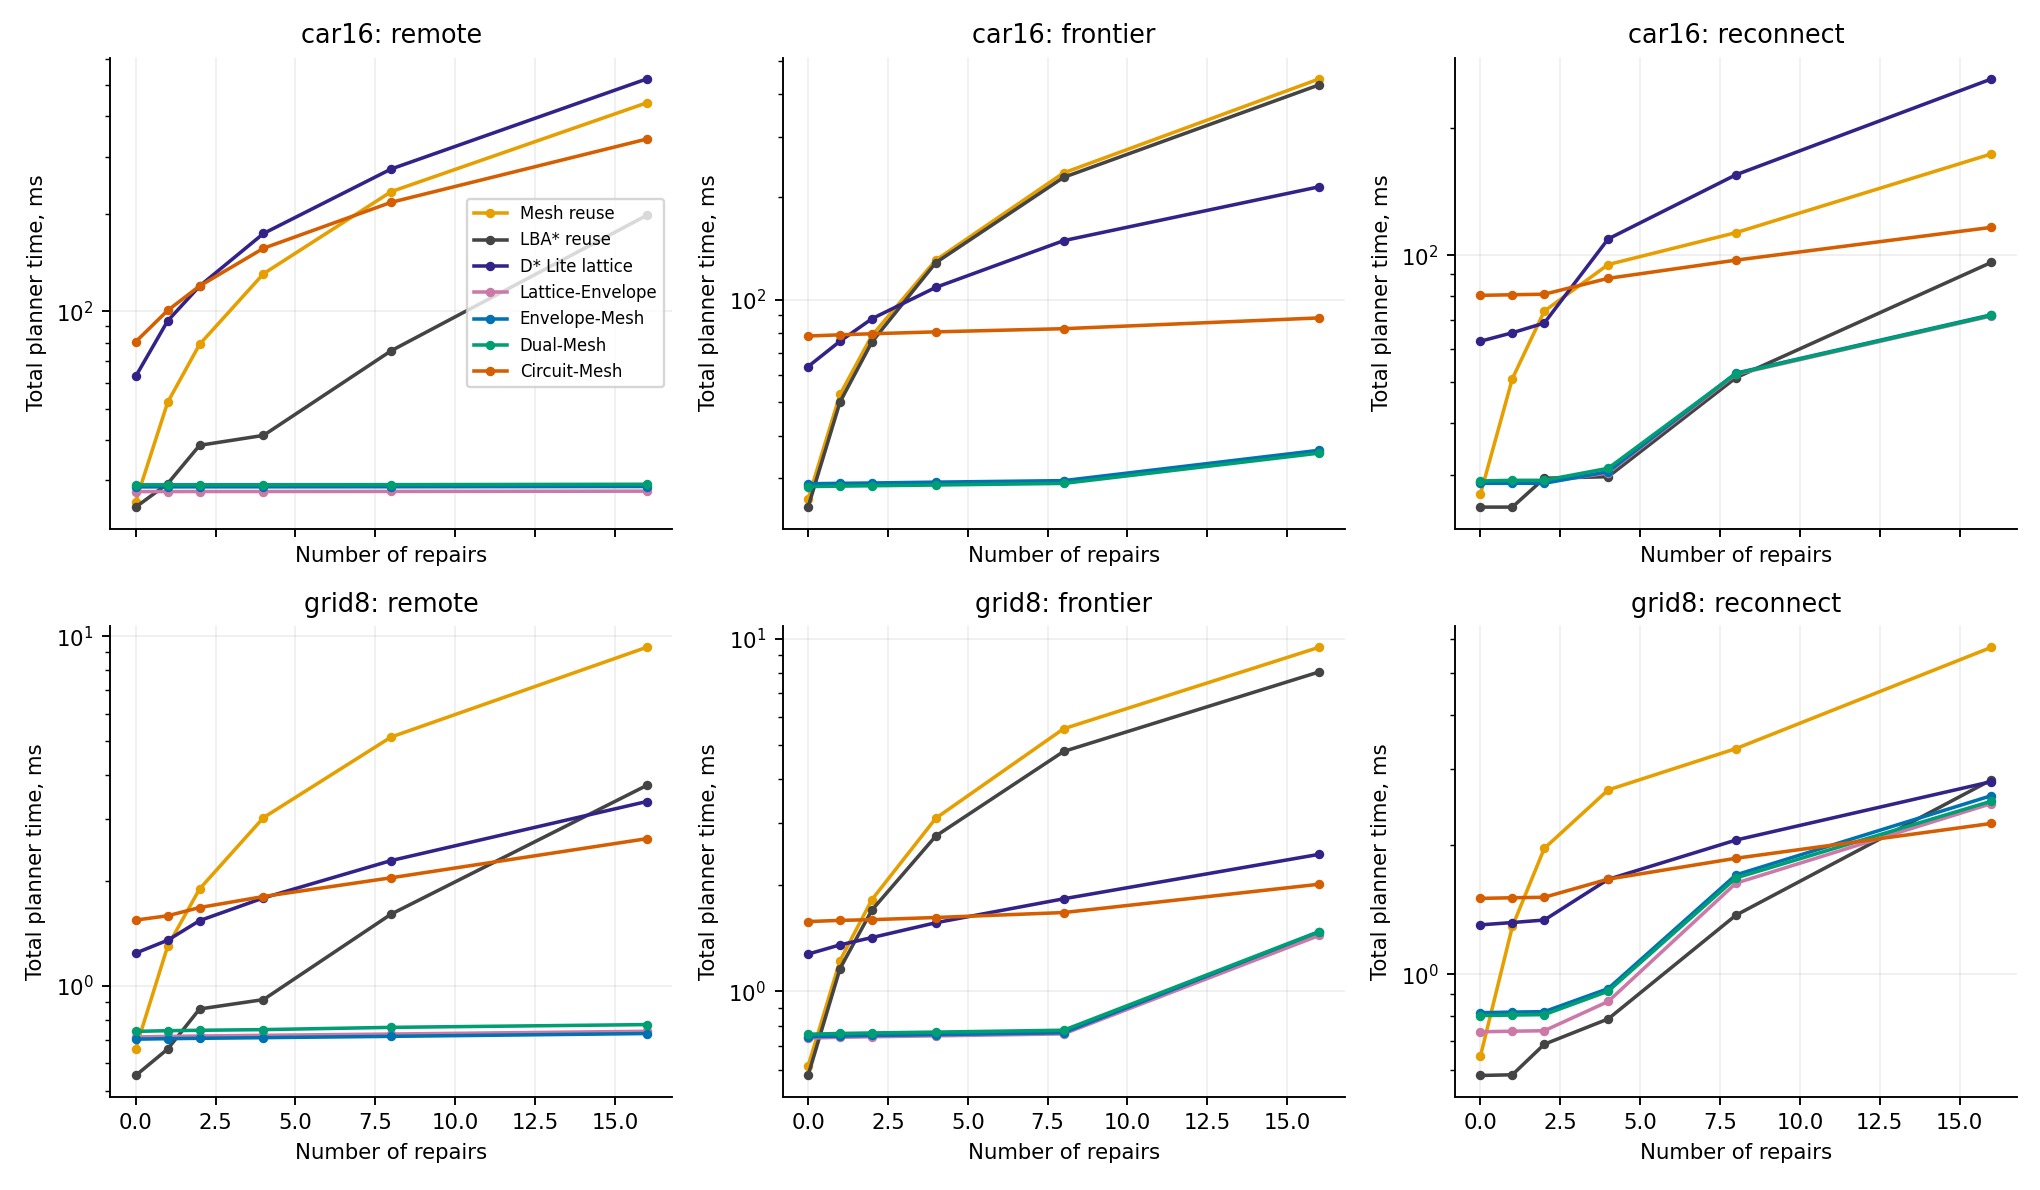

In [3]:
family = pd.read_csv(ad/'family_pairs.csv')
display(family[family.cohort.eq('separator') & family.method.isin(new) & family.baseline.isin(['lattice_envelope','mesh_reuse','dstar_lattice'])][['control','family','method','baseline','full_speedup','repair_speedup']])
display(Image(filename=str(root/'docs/mesh_envelope/figures/amortization.png')))

,cohort,control,method,configurations,complete
0,navigation_dynamic,car16,batch_mpgaa,12,7
1,navigation_dynamic,car16,boundary_mesh,12,6
2,navigation_dynamic,car16,boundary_mpgaa,12,7
3,navigation_dynamic,car16,circuit_mesh,12,6
4,navigation_dynamic,car16,cmesh_dstar,12,7
...,...,...,...,...,...
105,separator,grid8,mesh_cold,12,12
106,separator,grid8,mesh_reuse,12,12
107,separator,grid8,mesha,12,12
108,separator,grid8,mpgaa,12,12


actual_cr_pct            clamped_phases    
                               min        max            min max
control map                                                     
car16   AR0700            5.000000  20.000000              0   0
        Berlin            4.998779  20.001221              0   0
        MA_maze96         4.991319  13.541667              0   2
        MA_random96       0.000000   4.991319              0   0
        MA_room96         0.000000   4.991319              0   0
        arena             0.000000   4.997918              0   0
grid8   AR0700            5.000000  20.000000              0   0
        Berlin            4.998779  20.001221              0   0
        MA_maze512        5.000305  12.304688              0   9
        MA_random512      5.000305  19.999695              0   0
        MA_room512        5.000305  19.999695              0   0
        arena             0.000000   4.997918              0   0
        random50_p10      0.000000   5.040000              0   0
        random50_p20      0.000000   5.040000              0   0
        random50_p30      0.000000   5.040000              0   0
        random50_p40      5.040000  20.000000              0   0

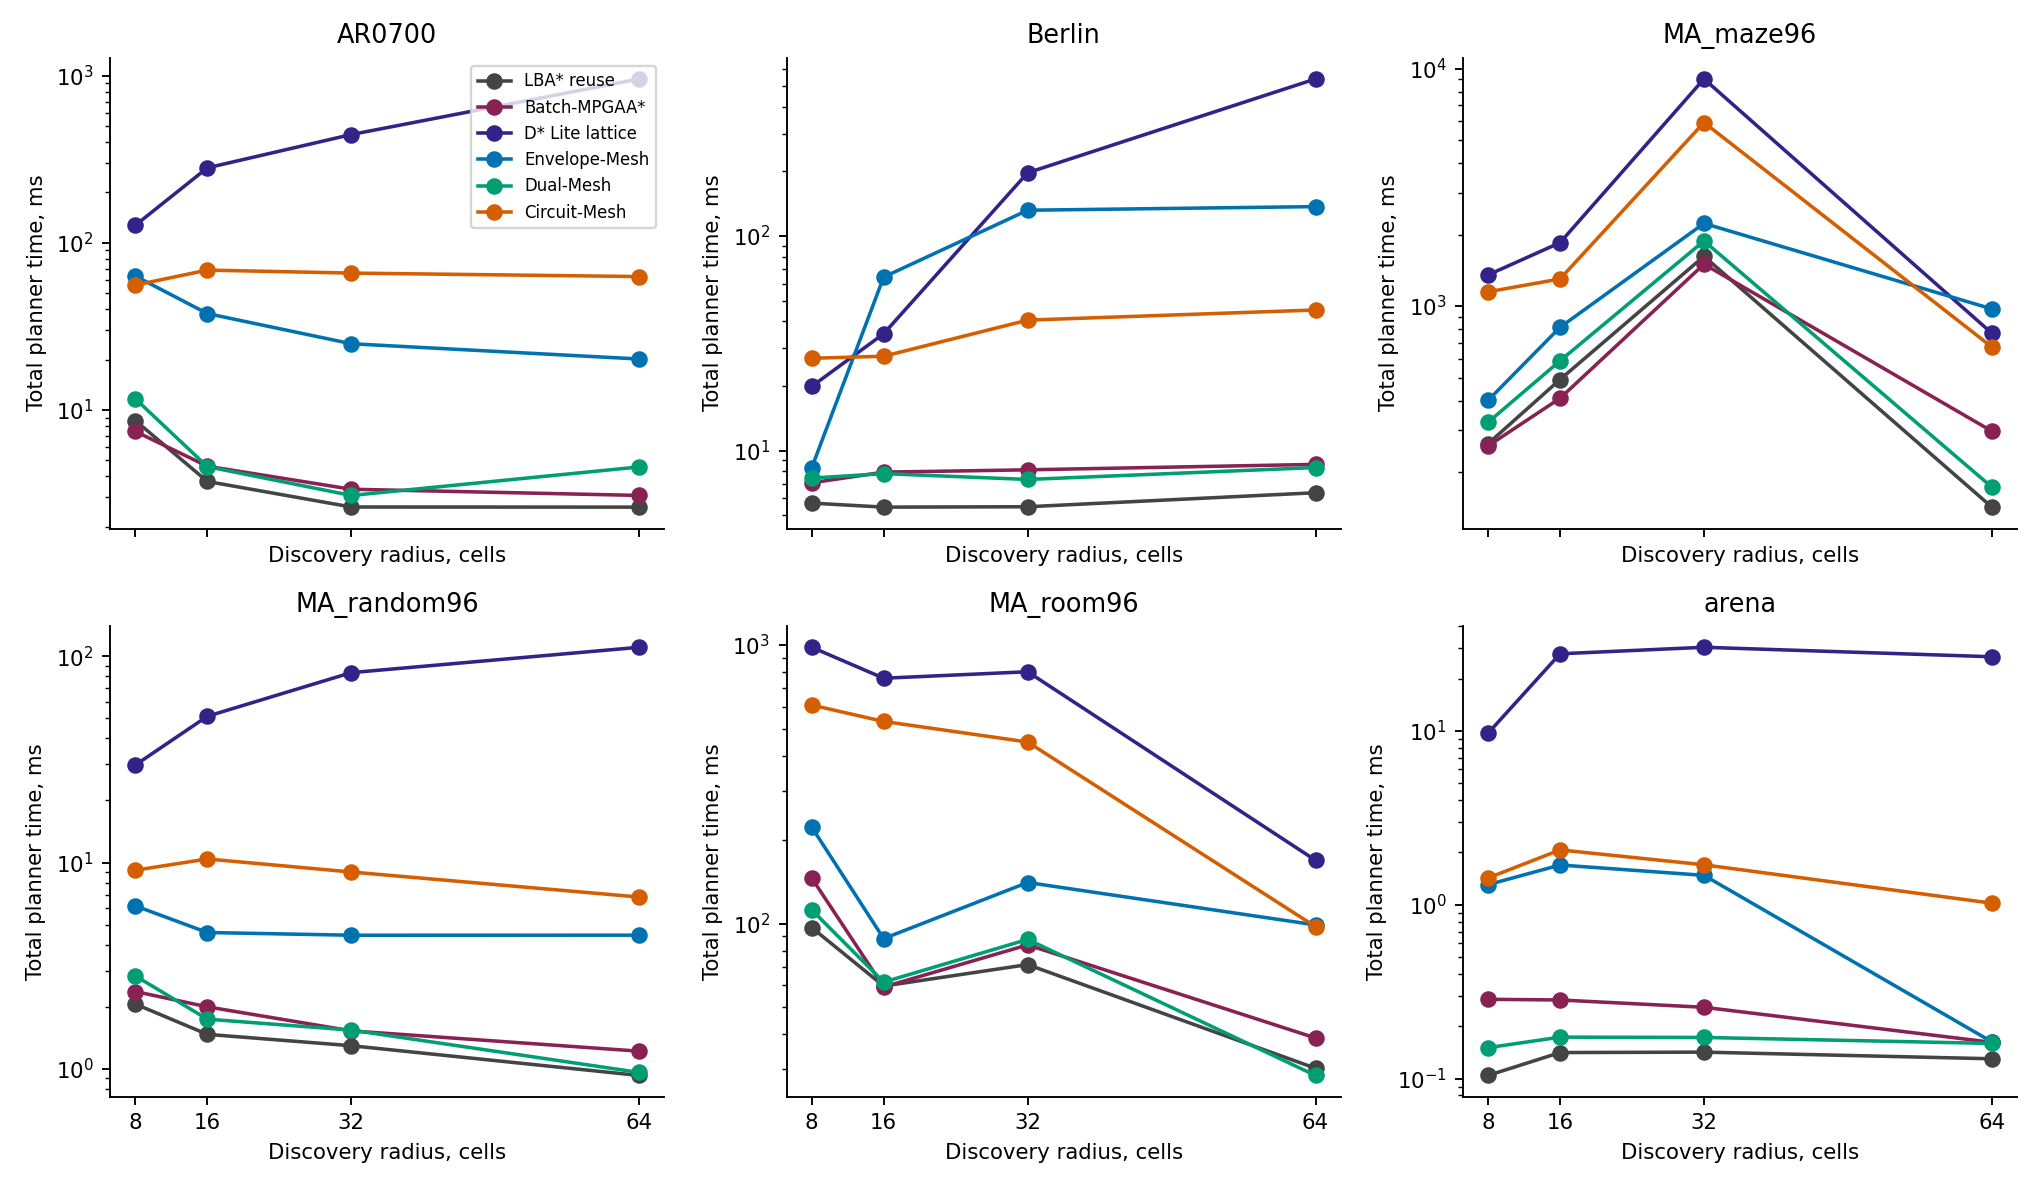

In [4]:
display(pd.read_csv(ad/'completion.csv'))
changes = pd.read_csv(ad/'actual_changes.csv')
display(changes.groupby(['control','map'])[['actual_cr_pct','clamped_phases']].agg(['min','max']))
display(Image(filename=str(root/'docs/mesh_envelope/figures/discovery_radius.png')))

## Second-stage SMD-A*

Fresh shared-backend comparisons, gap-off and eager-open controls. Reused replay inputs are exploratory; alternate-root navigation is reported separately. No seconds are pooled between stages.

,cohort,control,panel,baseline,configurations,pairs,full_speedup,repair_speedup,memory_multiplier,wins10
1,navigation_dynamic,car16,holdout,best_control,12,9,0.384728,0.034561,2.571898,0
6,navigation_dynamic,car16,holdout,md_batch,12,9,0.938595,0.837499,1.001980,0
7,navigation_dynamic,car16,holdout,smd_plain,12,9,1.017296,1.039692,1.000000,1
9,navigation_unknown,car16,holdout,best_control,24,22,0.269741,0.427919,1.918624,0
14,navigation_unknown,car16,holdout,md_batch,24,22,0.338534,0.609024,1.281947,0
15,navigation_unknown,car16,holdout,smd_plain,24,22,0.986334,1.021634,1.000000,0
17,replay,car16,history,best_control,4,4,0.967392,1.121193,1.000000,2
20,replay,car16,history,lazy_blocks_batch,4,4,0.989371,1.014095,1.000000,2
23,replay,car16,history,md_batch,4,4,1.023071,1.548473,1.000000,2
24,replay,car16,history,smd_plain,4,4,1.007202,1.033136,1.000000,2


,cohort,control,method,configurations,complete
0,navigation_dynamic,car16,batch_mpgaa,12,9
1,navigation_dynamic,car16,boundary_mesh,12,10
2,navigation_dynamic,car16,conditional_dstar,12,10
3,navigation_dynamic,car16,lba_reuse,12,8
4,navigation_dynamic,car16,md_astar,12,9
5,navigation_dynamic,car16,md_batch,12,9
6,navigation_dynamic,car16,smd_batch,12,9
7,navigation_dynamic,car16,smd_plain,12,9
8,navigation_unknown,car16,batch_mpgaa,24,24
9,navigation_unknown,car16,boundary_mesh,24,24


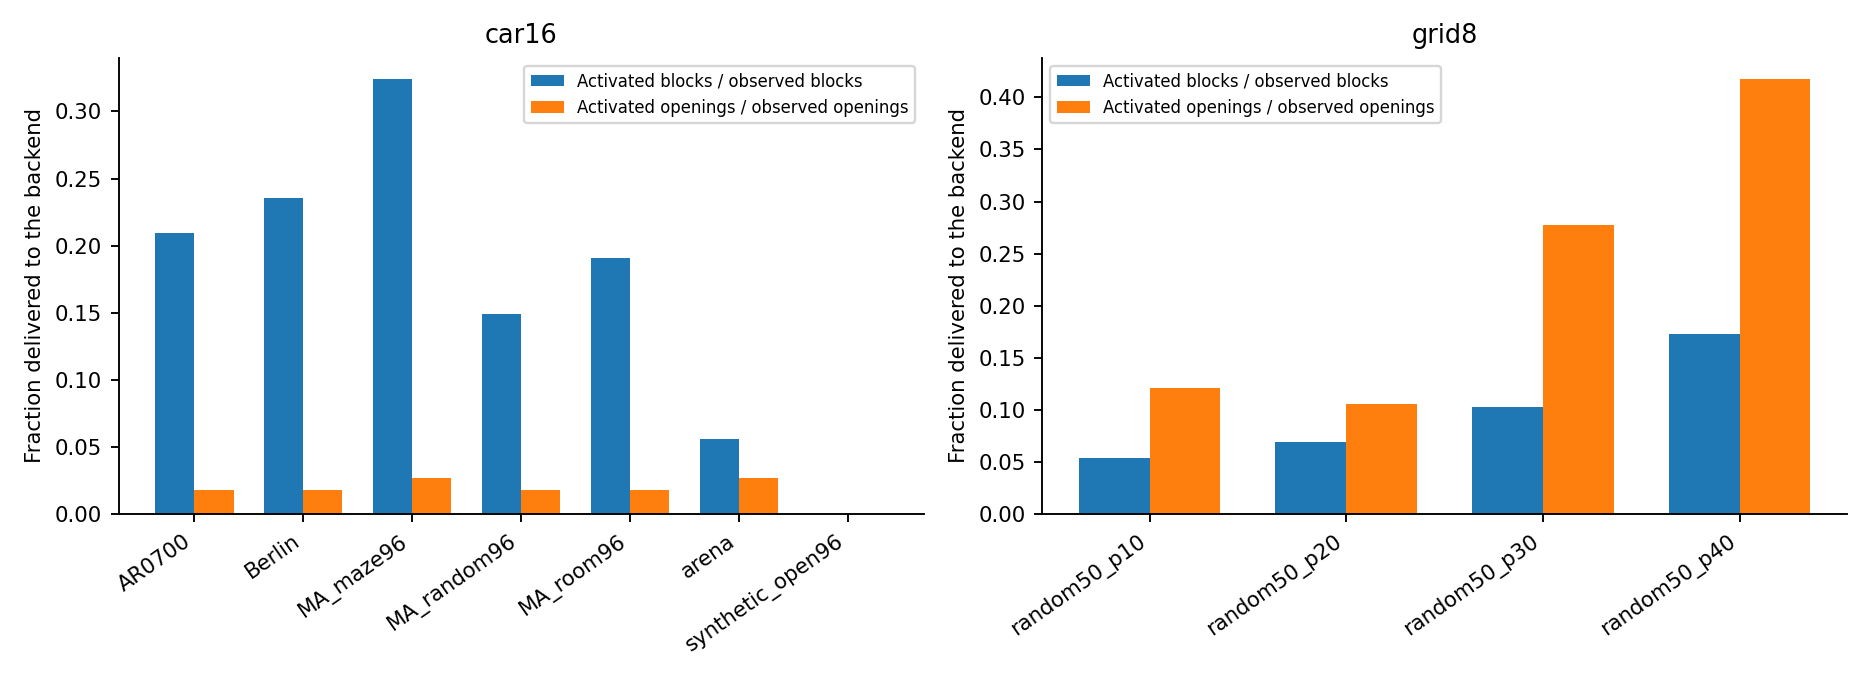

In [5]:
sad = root / 'cpp/mesh_symmetric/results/full/analysis'
smeta = json.loads((sad/'analysis.json').read_text())
assert smeta['status'] == 'passed'
for name, sha in smeta['tables_sha256'].items():
    assert hashlib.sha256((sad/name).read_bytes()).hexdigest() == sha
ss = pd.read_csv(sad/'summary.csv')
display(ss[ss.baseline.isin(['best_control','md_batch','lazy_blocks_batch','smd_plain'])])
display(pd.read_csv(sad/'completion.csv'))
display(Image(filename=str(root/'docs/mesh_symmetric/figures/activation.png')))

The limited literature review identifies MeshA*, D* Lite/LPA*, MPGAA*, Lifelong-GLS/Generalized D*, and IPC/IDPC as related work. Their results do not establish priority or universal superiority for this artifact. See both reports and related_work.md for the exact mesh-specific claims, per-map losses, construction overhead, caps, memory maxima, and omitted external implementations.